# TechPath ML Engine using Logistic Regression

**Team members:** Hellen Mutemi (179581) · Mediatrice Kasongo (190013) · Tumaini Wekesa (189813)

## 1.Identify the ML approach and algorithms that are relevant to the dataset & expected output of your application.
TechPath is an AI mobile app that builds a personalized career-skills roadmap for technology students. A student will type their career and the AI app will show the skills to learn, explain each one and show links to learning resources

**The ML engine** uses a *Retrieval Augmented Generation framework* where a student's text is matched to the most relevant career path and the skill nodes in the dataset. 
Our dataset labels every skill node with the `career_path` it belongs to meaning that the this is a **supervised multi-class text classification** where given a piece of text describing a skill or interest, predict which career path it belongs to.


In [1]:
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, top_k_accuracy_score

RANDOM_STATE =  42

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_colwidth", 120)


## 2.critically detail the data cleaning process taken from exploration to the final dataset for modelling. As part of the EDA, derive at least 4 observations from the dataset
The dataset was scrapped from the roadmap.sh Github repository(*https://github.com/nilbuild/developer-roadmap*) and a python script used to convert it from json to csv.

In [2]:
# Loading the raw dataset
raw = pd.read_csv("roadmap_dataset.csv")
print("Attributes (rows, columns)", raw.shape)
raw.head()

Attributes (rows, columns) (10634, 10)


,career_path,topic_slug,node_id,title,description,courses,articles,official_docs,videos,opensource
0,ai-agents,acting--tool-invocation,sHYd4KsKlmw5Im3nQ19W8,Acting / Tool Invocation,"Acting, also called tool invocation, is the step where the AI chooses a tool and runs it to get real-world data or t...",NaN,What are Tools in AI Agents? (https://huggingface.co/learn/agents-course/en/unit1/tools) | What is Tool Calling in A...,NaN,NaN,NaN
1,ai-agents,agent-loop,Eih4eybuYB3C2So8K0AT3,Agent Loop,"An agent loop is the cycle that lets an AI agent keep working toward a goal. First, the agent gathers fresh data fro...",NaN,What is an Agent Loop? (https://huggingface.co/learn/agents-course/en/unit1/agent-steps-and-structure) | Let's Build...,NaN,NaN,NaN
2,ai-agents,agno,PY5WTJgRnXiYeOM6BBUvn,Agno,Agno is a Python framework designed to streamline the process of building AI agents. It offers tools and abstraction...,NaN,NaN,Agno Docs (https://docs.agno.com/),Building Your First Agent With AGNO AGI ( Previously Phidata ) | For Complete Begineers (https://www.youtube.com/wat...,agno (https://github.com/agno-agi/agno)
3,ai-agents,anthropic-tool-use,1EZFbDHA5J5_5BPMLMxXb,Anthropic Tool Use,Anthropic Tool Use lets you connect a Claude model to real software functions so the agent can do useful tasks on it...,NaN,NaN,Anthropic Tool Use (https://docs.anthropic.com/en/docs/build-with-claude/tool-use/overview),NaN,NaN
4,ai-agents,api-requests,52qxjZILV-X1isup6dazC,API Requests,API requests let an AI agent ask another service for data or for an action. The agent builds a short message that fo...,NaN,Introduction to APIs - MDN Web Docs (https://developer.mozilla.org/en-US/docs/Learn_web_development/Extensions/Clien...,NaN,NaN,NaN


In [3]:
# Data types and non-null counts
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10634 entries, 0 to 10633
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   career_path    10634 non-null  str  
 1   topic_slug     10615 non-null  str  
 2   node_id        10625 non-null  str  
 3   title          10632 non-null  str  
 4   description    10605 non-null  str  
 5   courses        299 non-null    str  
 6   articles       7000 non-null   str  
 7   official_docs  4647 non-null   str  
 8   videos         4297 non-null   str  
 9   opensource     447 non-null    str  
dtypes: str(10)
memory usage: 830.9 KB


**career_path** : the roadmap a skill belongs to, e.g. aws, blockchain
**topic_slug**, **node_id**: the internal identifiers from roadmap.sh
**title**, **description**: the skill name and its explanation
**courses**, **articles**, **official_docs**, **videos**, **opensource**: these are the learning resource links

### Missing Values

In [7]:
missing = pd.DataFrame({
    "missing count": raw.isna().sum(),
    "missing percentage":(raw.isna().mean()*100).round(1),
}).sort_values("missing count",ascending=False)
missing

,missing count,missing percentage
courses,10335,97.2
opensource,10187,95.8
videos,6337,59.6
official_docs,5987,56.3
articles,3634,34.2
description,29,0.3
topic_slug,19,0.2
node_id,9,0.1
title,2,0.0
career_path,0,0.0


Dropping rows without `title` or `description` because these are the model's main input and if either one is missing it becomes unusable. But the resource columns are empty but we keep them because not every skill has a course

In [8]:
df = raw.copy()
before = len(df)

df = df.dropna(subset=["title", "description"])
print(f"Dropped {before-len(df)} rows with missing title/description, current is 10604 rows")

Dropped 30 rows with missing title/description, current is 10604 rows


### Duplicates

We look for duplicates in general, then we go on to drop rowa which have the same career_path and title because we consider these duplicates

In [9]:
before = len(df)
df = df.drop_duplicates()
print(f"Dropped {before-len(df)} duplicate rows, current rows are {len(df)}")

before = len(df)
df = df.drop_duplicates(subset=["career_path", "title"])
print(f"Dropped {before-len(df)} rows, current rows are now, {len(df)}")


Dropped 0 duplicate rows, current rows are 10604
Dropped 308 rows, current rows are now, 10296


### Cleaning the text
Some descriptions can contain leftovers from scraping, like markdown headings and links and raw urls, so we therefore remove them

In [10]:
noisy = df[df["description"].str.contains(r"=====|\[@|https?://", regex=True)]
print("Rows with markdown or URL dirty data:", len(noisy))
noisy["description"].head(3).tolist()

Rows with markdown or URL dirty data: 95


['Langchain =========  Haystack is an open-source Python framework that helps you build search and question-answering agents fast. You connect your data sources, pick a language model, and set up pipelines that find the best answer to a user’s query. Haystack handles tasks such as indexing documents, retrieving passages, running the model, and ranking results. It works with many back-ends like Elasticsearch, OpenSearch, FAISS, and Pinecone, so you can scale from a laptop to a cluster. You can add features like summarization, translation, and document chat by dropping extra nodes into the pipeline. The framework also offers REST APIs, a web UI, and clear tutorials, making it easy to test and deploy your agent in production.',
 "[Readme.com](http://Readme.com) is an invaluable tool in the realm of API Design, renowned for providing a collaborative platform for creating beautiful, dynamic and intuitive documentation. It's a tool which aids developers in outlining clear, comprehensive docu

In [11]:
def clean_text(text: str) -> str:
    """Normalise one piece of text."""
    text = str(text).lower()                               # 1. lowercase so 'Git' and 'git' are the same word
    text = re.sub(r"\[([^\]]*)\]\([^)]*\)", r"\1", text)   # 2. markdown link [label](url) -> label
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)      # 3. remove raw URLs
    text = re.sub(r"@\w+@", " ", text)                     # 4. remove roadmap.sh tags like @official@
    text = re.sub(r"[=#*_`>-]{2,}", " ", text)              # 5. remove markdown heading/rule symbols
    text = re.sub(r"[^a-z0-9+#.\s]", " ", text)             # 6. keep letters, digits and tech symbols (c++, c#, .net)
    text = re.sub(r"\s+", " ", text).strip()                # 7. collapse repeated spaces
    return text

# The model input is the skill title + its description
df["text"] = (df["title"] + ". " + df["description"]).apply(clean_text)

# Before vs after for one example
example = noisy.index[0]
print("BEFORE:", df.loc[example, "description"][:200])
print("AFTER: ", df.loc[example, "text"][:200])

BEFORE: Langchain =========  Haystack is an open-source Python framework that helps you build search and question-answering agents fast. You connect your data sources, pick a language model, and set up pipeli
AFTER:  haystack. langchain haystack is an open source python framework that helps you build search and question answering agents fast. you connect your data sources pick a language model and set up pipelines


Dropping rows whose description has fewer than 10 words

In [12]:
df["desc_words"] = df["description"].apply(clean_text).str.split().str.len()

print(df.loc[df["desc_words"] < 10, "description"].tolist())

before = len(df)
df = df[df["desc_words"] >= 10]
print(f"Dropped {before-len(df)} rows with less than 10 description words, currently {len(df)} rows")

['- [@official@Google Engineering Practices](https://github.com/google/eng-practices)', 'Articles ========', 'Articles ========']
Dropped 3 rows with less than 10 description words, currently 10293 rows


Analyzing career paths and the number of skills they have

Number of career paths are: 93
count     93.0
mean     110.7
std       47.9
min        1.0
25%       91.0
50%      109.0
75%      141.0
max      292.0
Name: count, dtype: float64


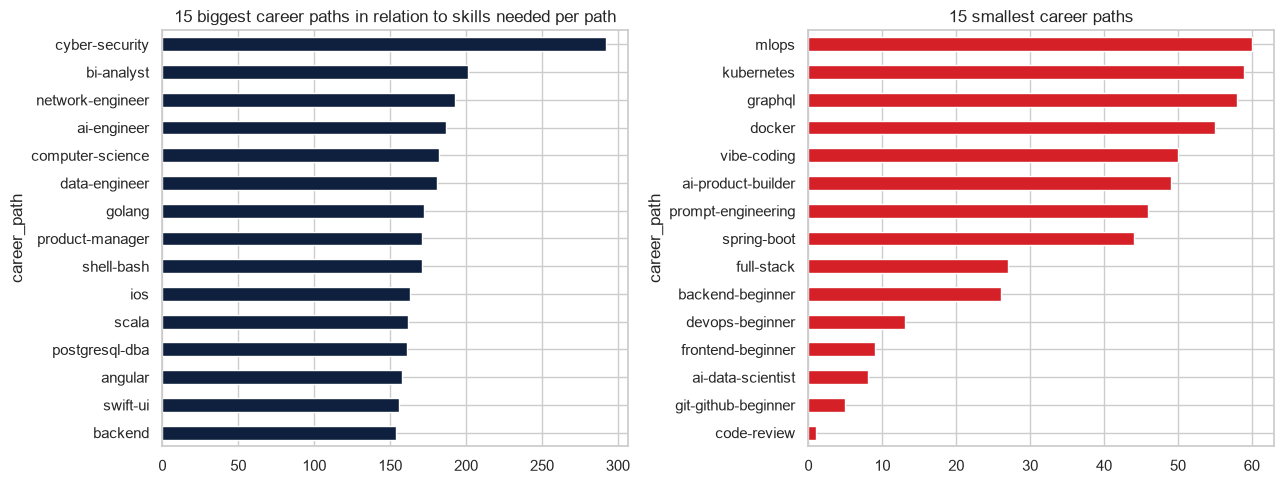

In [15]:
counts = df["career_path"].value_counts()
print("Number of career paths are:", counts.size)
print(counts.describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
counts.head(15).plot(kind="barh", ax=axes[0], color="#0E203E")
axes[0].set_title("15 biggest career paths in relation to skills needed per path")
axes[0].invert_yaxis()
counts.tail(15).plot(kind="barh", ax=axes[1], color="#D42026")
axes[1].set_title("15 smallest career paths")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

**Decision** Because some paths have very few skills, we dropped them because a 5-fold cross validation needs at least 5 examples per class in every split. Therefore we only kept those career paths with at least 30 skills

In [ ]:
# Keep only career paths with at least 30 skill nodes
MIN_SKILLS = 30
small_paths = counts[counts < MIN_SKILLS]
print("paths removed:", small_paths.to_dict())

before = len(df)
df = df[df["career_path"].isin(counts[counts >= MIN_SKILLS].index)].reset_index(drop=True)
print(f"Dropped {before-len(df)} rows from {len(small_paths)} small paths, currently {len(df)} rows remaining and ",f"{df["career_path"].nunique()} career paths")

paths removed: {'full-stack': 27, 'backend-beginner': 26, 'devops-beginner': 13, 'frontend-beginner': 9, 'ai-data-scientist': 8, 'git-github-beginner': 5, 'code-review': 1}
Dropped 0 rows from 7 small paths, currently 10204 rows remaining and  86 career paths


### Exploratory data analysis EDA

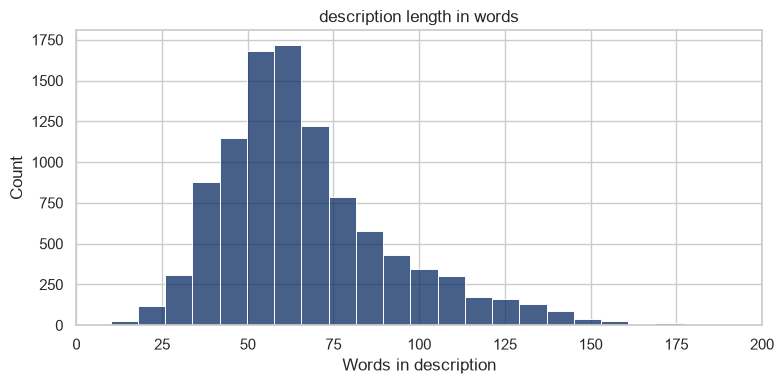

count    10204.0
mean        67.3
std         27.5
min         10.0
25%         50.0
50%         62.0
75%         79.0
max        487.0
Name: desc_words, dtype: float64


In [18]:
plt.figure(figsize=(8,4))
sns.histplot(df["desc_words"], bins=60, color="#092B62")
plt.title("description length in words")
plt.xlabel("Words in description")
plt.xlim(0,200)
plt.tight_layout()
plt.show()

print(df["desc_words"].describe().round(1))

Checking how often does each kind of learning resource exist

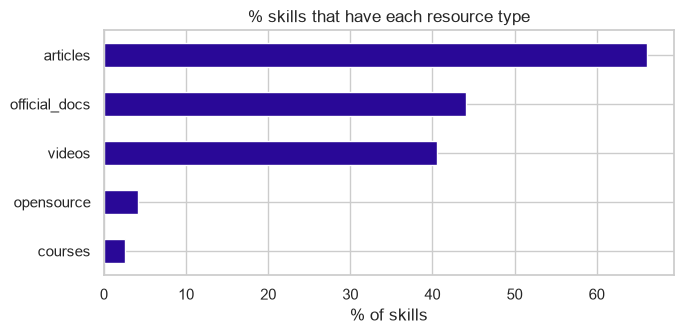

courses           2.6
opensource        4.2
videos           40.5
official_docs    44.1
articles         66.1
dtype: float64
9.5% skills with no resource link at all


In [19]:
resource_cols = ["articles", "official_docs", "videos", "opensource", "courses"]
coverage = (df[resource_cols].notna().mean()*100).round(1).sort_values()
coverage.plot(kind="barh", figsize=(7, 3.5), color="#290897")
plt.title("% skills that have each resource type")
plt.xlabel("% of skills")
plt.tight_layout()
plt.show()

no_resource = (df[resource_cols].notna().sum(axis=1) == 0).mean()*100
print(coverage)
print(f"{no_resource:.1f}% skills with no resource link at all")

Checking for the most distinctive words per career path (highest average TF-IDF score)

In [20]:
# This checks that each path has its own vocabulary which the model will rely on
probe = TfidfVectorizer(stop_words="english", min_df=2)
X_probe = probe.fit_transform(df["text"])
terms = np.array(probe.get_feature_names_out())

for path in ["cyber-security", "android", "data-engineer", "product-manager", "devops"]:
    rows = (df["career_path"] == path).values
    mean_scores = np.asarray(X_probe[rows].mean(axis=0)).ravel()
    top = terms[mean_scores.argsort()[::-1][:8]]
    print(f"{path:16s} -> {', '.join(top)}")


cyber-security   -> security, network, access, systems, data, cybersecurity, devices, information
android          -> android, app, kotlin, ui, apps, jetpack, google, user
data-engineer    -> data, cloud, storage, database, infrastructure, systems, etl, warehouse
product-manager  -> product, manager, market, managers, user, management, understanding, customer
devops           -> cloud, infrastructure, applications, server, management, platform, servers, software


### EDA Observations

1. **The classes are imbalanced** - Where after cleaning, the largest path `cyber-security` had 292 skills which as almost 10 times as many as the smallest path
2. **Many skills are shared across roadmaps** - Around 1,000 skill titles apppear on more than one roadmap e.g. "Git". This sets a ceiling on accuracy where a git node belongs to many careers
3. **Descriptions are short and consistent paragraphs** - Most descriptions are 50 to 80 words
4. **Each career path has a recognisable vocabulary** - e.g. Security terms for cyber-security

In [22]:
# The final modelling dataset
final = df[["career_path", "title", "text"]].copy()
print("(rows, columns):", final.shape, "career paths: ", final["career_path"].nunique())

print(f"Original raw rows: {len(raw)}")
print(f"Final rows: {len(final)} ({len(raw)-len(final)} removed, {100*(len(raw)-len(final))/len(raw):.1f}%)")
final.head()

(rows, columns): (10204, 3) career paths:  86
Original raw rows: 10634
Final rows: 10204 (430 removed, 4.0%)


,career_path,title,text
0,ai-agents,Acting / Tool Invocation,acting tool invocation. acting also called tool invocation is the step where the ai chooses a tool and runs it to ge...
1,ai-agents,Agent Loop,agent loop. an agent loop is the cycle that lets an ai agent keep working toward a goal. first the agent gathers fre...
2,ai-agents,Agno,agno. agno is a python framework designed to streamline the process of building ai agents. it offers tools and abstr...
3,ai-agents,Anthropic Tool Use,anthropic tool use. anthropic tool use lets you connect a claude model to real software functions so the agent can d...
4,ai-agents,API Requests,api requests. api requests let an ai agent ask another service for data or for an action. the agent builds a short m...


## 3. Describe the modelling approach taken on the identified base model. Ensure you have applied appropriate measures as guided by other similar approaches to verify the validity of the results e.g. applying elbow method for K-means clustering, cross validation for classification and regularisation for regression tasks.

1. **TF-IDF** (Term Frequency-Inverse Document Frequency) to turn each skill text into a list of numbers, 1 per word. A word scores high when it is frequent in this text but rare across the whole dataset e.g. "kuberneted" and it scores low when it is common everywhere e.g. "use"
2. **Logistic regression** - learns a weight for every word for every career path ,and to classify a new text it adds up the weights of the words present and turns the total into a probability for each career path.
We used logistic regression because it is fast and outputs probabilities, enabling our app to show something like top 3 most likely career paths

### Validation Plan
- **Train/test split (80/20, stratified)** - Split into 80 20 and test set is only used once at the end
- **Hyper parameter tuning with 5-fold stratified cross-validation** - where we split the 80% training into 5 chunks and we learn from 4 chunks and test from the 5th and we repeat 5 times so each chunk gets a turn as the practice test. Then average the 5 scores. We will tune `C` to control how closely the model fits the training data. A small `C` is where the model will learn general patterns and ignore small details, while a large `C` is where the model fits training examples closely
- **Metrics** - Accuracy(involves what % did it get right), Macro-F1(involves how well it did on each career averaged equally), Top 3 accuracy(invovles if the correct career was in its top 3 guesses )


In [31]:
X = final["text"]
y = final["career_path"]

# Holding out 20% as final untouched set, stratify=y keeps every career path in the same propotion in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train on:", X_train.shape[0], "rows", "test on: ", X_test.shape[0], "rows")


Train on: 8163 rows test on:  2041 rows


In [32]:
# The pipeline bundles TF-IDF and the classifier so that inside cross-validation TF-IDF is
# refitted on each training fold only which prevents test words from leaking into training

def make_tfidf():
    return TfidfVectorizer(
        stop_words="english", #dropping very common words like and, the
        ngram_range=(1,2), #making the model read single words and two words phrases
        min_df=2, #ignore words that only appear in fewer than 2 descriptions
        sublinear_tf=True, #dampening the effect of a word repeated many times
    )

base_pipeline = Pipeline([
    ("tfidf", make_tfidf()),
    ("clf", LogisticRegression(max_iter=2000)) #logistic regression learns words weights by adjusting them gradually in many small rounds, the default limit is 100, but 2000 gives it enough rounds to finish properly

])

# A rule for splitting data into practice and test folds, 5 folds and mixes the rows before
# splitting and uses the seed of 42 so the shuffle is the same everytime and results are
# reproducible
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [26]:
# Hyperparameter search with regularization strength C and n-gram range
param_grid = {
    "clf__C": [1, 10, 30],
    "tfidf__ngram_range": [(1,1), (1,2)],
}

start = time.time()
grid = GridSearchCV(base_pipeline, param_grid, cv=cv, scoring="f1_macro", n_jobs=-1)
grid.fit(X_train, y_train)
print(f"grid search finished in {time.time() - start:.0f}s")
print("Best settings:", grid.best_params_)
print(f"Best mean cross-validation macro-F1: {grid.best_score_:.3f}")

grid search finished in 299s
Best settings: {'clf__C': 30, 'tfidf__ngram_range': (1, 2)}
Best mean cross-validation macro-F1: 0.696


It is worth noting that the code above consumed a significant of RAM, aroudn 10GB becuase of the line `n_jobs=-1` which allows it to utilize all the CPU cores at once

In [27]:
# Showing every combination tried so we can see the effect of regularisation
results = pd.DataFrame(grid.cv_results_)[
    ["param_clf__C", "param_tfidf__ngram_range", "mean_test_score", "std_test_score"]
].rename(columns={"param_clf__C": "C", "param_tfidf__ngram_range": "ngrams",
                  "mean_test_score": "cv_macro_f1", "std_test_score": "std"})
results["ngrams"] = results["ngrams"].astype(str)
results.sort_values("cv_macro_f1", ascending=False).round(3)

,C,ngrams,cv_macro_f1,std
5,30,"(1, 2)",0.696,0.010
3,10,"(1, 2)",0.690,0.010
4,30,"(1, 1)",0.690,0.009
2,10,"(1, 1)",0.689,0.010
0,1,"(1, 1)",0.643,0.008
1,1,"(1, 2)",0.621,0.007


Grid search showed that weaker regularisation (C ≥ 10) gave better results than stronger regularisation (C = 1), which did not fit the data well. The best result was achieved with C = 30 using unigrams and bigrams, with a macro-F1 score of 0.696 ± 0.010. However, the top four settings had similar results, showing that increasing C beyond 10 made little difference in performance.

### Final evaluation on the held-out test set

In [33]:
best_model = grid.best_estimator_   # already re-trained on the full training set by GridSearchCV

y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)

test_acc = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average="macro")
test_top3 = top_k_accuracy_score(y_test, y_proba, k=3, labels=best_model.classes_)

print(f"Test accuracy:       {test_acc:.3f}")
print(f"Test macro-F1:       {test_f1:.3f}")
print(f"Test top-3 accuracy: {test_top3:.3f}   (true path is among the model's 3 best guesses)")
print(f"Random guessing would score about {1 / y.nunique():.3f} accuracy")


Test accuracy:       0.726
Test macro-F1:       0.725
Test top-3 accuracy: 0.882   (true path is among the model's 3 best guesses)
Random guessing would score about 0.012 accuracy


In [34]:
# Per career path results showing which were easy and which are hard
report = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).T
per_class = report.drop(["accuracy", "macro avg", "weighted avg"]).sort_values("f1-score")

print("8 Hardest career paths:")
display(per_class.head(8)[["precision", "recall", "f1-score", "support"]].round(2))
print("8 easiest career paths:")
display(per_class.tail(8)[["precision", "recall", "f1-score", "support"]].round(2))

8 Hardest career paths:


,precision,recall,f1-score,support
r-programming,0.11,0.12,0.11,26.0
r,0.15,0.15,0.15,26.0
backend,0.24,0.19,0.21,31.0
devsecops,0.36,0.21,0.27,19.0
ai-product-builder,1.00,0.20,0.33,10.0
mlops,0.36,0.33,0.35,12.0
frontend,0.40,0.36,0.38,22.0
java,0.50,0.33,0.40,18.0


8 easiest career paths:


,precision,recall,f1-score,support
power-bi,0.96,0.93,0.95,29.0
kotlin,0.94,0.97,0.95,30.0
php,0.92,1.00,0.96,24.0
redis,1.00,0.93,0.96,29.0
product-manager,0.94,1.00,0.97,34.0
mongodb,1.00,0.95,0.98,21.0
engineering-manager,1.00,0.96,0.98,27.0
ai-red-teaming,1.00,1.00,1.00,13.0


In [37]:
# Pre-compute TF-IDF vectors for every skill once, using the trained model's vectoriser
tfidf = best_model.named_steps["tfidf"]
skill_vectors = tfidf.transform(final["text"])

def recommend(student_text, top_paths=3, top_skills=5):
    """Return the most likely career paths and the closest skills for a student's free-text interest."""
    cleaned = clean_text(student_text)
    proba = best_model.predict_proba([cleaned])[0]
    best = np.argsort(proba)[::-1][:top_paths]

    print(f'Student: "{student_text}"')
    for rank, idx in enumerate(best, 1):
        print(f"  {rank}. {best_model.classes_[idx]:20s} probability {proba[idx]:.2f}")

    # Retrieval step: cosine similarity between the query and every skill in the top path
    top_path = best_model.classes_[best[0]]
    in_path = (final["career_path"] == top_path).values
    sims = (skill_vectors[in_path] @ tfidf.transform([cleaned]).T).toarray().ravel()
    closest = final.loc[in_path, "title"].values[np.argsort(sims)[::-1][:top_skills]]
    print(f"  Closest skills on the '{top_path}' roadmap: {', '.join(closest)}\n")

recommend("I want to build mobile apps for Android phones")
recommend("I like protecting systems from hackers and analysing attacks")
recommend("I enjoy working with data pipelines and large databases")
recommend("I want to train machine learning models")
recommend("I want to be a quantitative programmer")

Student: "I want to build mobile apps for Android phones"
  1. android              probability 0.66
  2. data-engineer        probability 0.03
  3. backend              probability 0.02
  Closest skills on the 'android' roadmap: Activity, Jetpack Benchmark, Hilt, Google Play Services, Storage

Student: "I like protecting systems from hackers and analysing attacks"
  1. cyber-security       probability 0.13
  2. backend              probability 0.04
  3. software-architect   probability 0.03
  Closest skills on the 'cyber-security' roadmap: APT, HackTheBox, Common Hacking Tools, Bus, Salting

Student: "I enjoy working with data pipelines and large databases"
  1. data-engineer        probability 0.58
  2. python-data-analysis probability 0.04
  3. forward-deployed-engineer probability 0.03
  Closest skills on the 'data-engineer' roadmap: Data Pipelines, Luigi, Skills and Responsibilities, Prefect, What is Data Engineering?

Student: "I want to train machine learning models"
  1. mlops 

### 4. Determine other methods that can be used to further validate the results of the base model. 

To validate performance of the base model an effective method is to benchmark it against alternative algorithms. THis can include building several candidate models e.g. Naive baseline(majority class dummy classifier), a probabilistic model(Multinomial naive bayes), a distance based model(Cosine K-Nearest neighbours) each sharing the same TF-IDF extraction pipeline to ensure fair comparison without data leakage.

Each candidate can be evaluated through 5-fold stratified cross validation on the training set to check stability and consistency across folds. By us comparing their accuracy and macro-F1 scores side by side in a structured benchmark we can confirm if the model's performance is acttually strong or an alternative architecture yields superior and reliable results